# Практическая работа №1 (ПР1). Профиль качества данных COVID-рентгеновского датасета

**Предметная область.** Компьютерное зрение в медицине: автоматическая классификация
фронтальных рентгенограмм грудной клетки по признаку COVID-19 («COVID» против «Normal»).
Задача критическая по безопасности: ложный negative (пропуск COVID-случая) влечёт
распространение инфекции и задержку лечения; ложный positive — лишние ПЦР-исследования.
Практический цикл БИИ (ПР1–ПР4 + итоговый отчёт) выполняется **поверх существующего проекта**
`minanabil96/mina_covid-xray-detector`: замороженный чекпоинт `best_model.pth` используется
только для инференса и анализа, **переобучение не производится**.

**Набор данных.** Источник — Kaggle-датасет *COVID-19 Radiography Database*
(`tawsifurrahman/covid19-radiography-database`, версия v4: COVID 3616 / Normal 10192),
на который ссылается исходный ноутбук `Covid_detector.ipynb`. Использовано локальное зеркало
`github.com/junelsolis/covid-19-radiography-dataset`: количество файлов по каждому классу
совпадает с v4 (COVID 3616 / Normal 10192 / Lung_Opacity 6012 / Viral Pneumonia 1345).
Полные метаданные, включая идентификаторы пациентов, в датасете отсутствуют; поэтому
приватной единицей в ПР4 назначается отдельное изображение — это будет задокументировано
как методологическое ограничение.

**Схема разбиения.** В точности как в исходном ноутбуке: `ImageFolder` по организованной
структуре `organized_data/{COVID,Normal}` (первые 3600 отсортированных файлов на класс),
разбиение 80/10/10 через `torch.utils.data.random_split` с генератором seed=42
→ 5760 / 720 / 720. Разбиение воспроизведено бит-в-бит: на тесте модель даёт ту же матрицу
ошибок (TP=354, FN=7, FP=5, TN=354), что и `training_history.json`
(accuracy 0.9833, recall 0.98061, precision 0.98607).

**Цель ПР1.** Построить количественный **многомерный** профиль качества данных: полнота,
валидность, уникальность, утечки train→test, сбалансированность, качество меток
(confident learning), репрезентативность (MMD/C2ST), специфичные для снимков статистики
(разрешение, яркость/контраст, размытие, NIQE/BRISQUE, коллимационные чёрные рамки).
Профиль затем объясняет, почему модель (ПР2/ПР3) и протокол атаки (ПР4) дают именно
такие результаты. Все ключевые оценки приводятся с 95% доверительными интервалами.

*Примечание по вычислительным ресурсам:* инференс выполняется на GPU (CUDA, NVIDIA RTX 2050);
чекпоинт заморожен и не переобучается, bootstrap выполняет ресэмплинг только по объектам.

*Терминологическая заметка по CI:* для долей используется интервал Уилсона (Wilson);
для средних величин — процентильный bootstrap (B=2000); для парных сравнений —
парный bootstrap; для MMD — пермутационный тест.


In [1]:
# Загрузка общих вспомогательных модулей и конфигурации воспроизводимости
import sys, json, os, time
from pathlib import Path

sys.path.insert(0, r"E:\ML_Projects\Covid")
import common

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from PIL import Image

from common import (SEED, set_seed, build_model, get_splits, eval_transforms,
                    PROJECT_ROOT, RESULTS_DIR, FIGURES_DIR, ORGANIZED_ROOT,
                    CLASS_NAMES, MEAN, STD, wilson_ci, fmt_ci)

import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

set_seed(SEED)
RESULTS_DIR.mkdir(exist_ok=True)
FIGURES_DIR.mkdir(exist_ok=True)
plt.rcParams["figure.dpi"] = 110
sns.set_theme(style="whitegrid")

repro = common.load_repro()
print("seed =", repro["seed"], "| bootstrap =", repro["bootstrap_iterations"],
      "| primary metric =", repro["primary_metric"])
print("baseline M(0) = {:.6f} CI95={:.4f}..{:.4f}".format(
    repro["baseline_metric_value"], *repro["baseline_95ci"]))

model = build_model()  # ResNet18 + Dropout/Linear-голова, веса = best_model.pth (заморожен)
model.eval()
from common import DEVICE
print("Устройство инференса:", DEVICE.type)
n_params = sum(p.numel() for p in model.parameters())
print("Модель:", repro["model_architecture"])
print(f"Параметров: {n_params:,}")


seed = 42 | bootstrap = 2000 | primary metric = Accuracy (test set is balanced: 361 COVID / 359 Normal; imbalance ratio 1.006)
baseline M(0) = 0.983333 CI95=0.9711..0.9904


Устройство инференса: cuda
Модель: ResNet18 (torchvision models.resnet18, ImageNet-pretrained at training time) + Sequential(Dropout(0.5), Linear(512, 2)); classes COVID=0, Normal=1; backbone frozen except layer4 (fine-tuned), earlier layers frozen
Параметров: 11,177,538


C:\Users\Mina Hanna\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\nn\modules\module.py:1357: UserWarning: expandable_segments not supported on this platform (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\c10/cuda/CUDAAllocatorConfig.h:35.)
  return t.to(


## Шаг 1. Описание набора данных

Ниже приведены фактические размеры классов по сплитам, баланс и классовая энтропия.
Классы индексируются алфавитно: COVID=0, Normal=1 (так назначает `ImageFolder`).
Классовая энтропия — мера неопределённости выбора класса при случайной выборке из набора;
для идеально сбалансированного бинарного набора она равна ln(2) ≈ 0.693.


In [2]:
# Шаг 1. Инвентаризация: размеры разбиений, баланс, энтропия
splits = get_splits()
n_total = sum(len(v) for v in splits.values())
rows = []
for name, samples in splits.items():
    nc = sum(1 for p, y in samples if y == 0)
    nn = sum(1 for p, y in samples if y == 1)
    rows.append((name, len(samples), nc, nn, nc / len(samples)))
df_counts = pd.DataFrame(rows, columns=["split", "n", "COVID", "Normal", "доля COVID"])
df_counts["imbalance_ratio(Normal/COVID)"] = df_counts["Normal"] / df_counts["COVID"]


def class_entropy(nc, nn):
    p = nc / (nc + nn)
    return float(-(p * np.log(p) + (1 - p) * np.log(1 - p)))


df_counts["class_entropy"] = [class_entropy(r.COVID, r.Normal) for r in df_counts.itertuples()]
display(df_counts)

print("Всего организовано файлов:", n_total,
      "| train:", len(splits["train"]), "| val:", len(splits["val"]),
      "| test:", len(splits["test"]))
print("Максимальная энтропия (равномерный класс):", round(class_entropy(1, 1), 4))


,split,n,COVID,Normal,доля COVID,imbalance_ratio(Normal/COVID),class_entropy
0,train,5760,2884,2876,0.500694,0.997226,0.693146
1,val,720,355,365,0.493056,1.028169,0.693051
2,test,720,361,359,0.501389,0.994460,0.693143


Всего организовано файлов: 7200 | train: 5760 | val: 720 | test: 720
Максимальная энтропия (равномерный класс): 0.6931


## Шаг 2/4. Полнота, валидность и базовые характеристики изображения

Для каждого организованного файла проверяется: (а) читается ли файл без ошибок —
оценка **полноты** (доля повреждённых/нечитаемых файлов); (б) **валидность** —
соответствие формату и домену: цветовой режим (grayscale ожидаем для рентгенограмм),
битовая глубина (ожидается ≤ 16 бит, но не «настоящий» 16-bit IEEE float), разрешение —
минимальная сторона < 128 px считается непригодной для скрининга после масштабирования
до 224×224; (в) базовые **X-ray-специфичные статистики**: средняя яркость, стандартное
отклонение (контраст), дисперсия лапласиана (грубая мера размытия) на исходном
разрешении, аспектное отношение. Результаты построчно сохраняются в
`results/pr1_image_stats.csv`.


In [3]:
# Шаг 2/4. Полнота + валидность + базовые статистики всех 7200 изображений
import cv2


def file_stats(path):
    st = {"path": path, "read_ok": 0, "mode": None, "w": 0, "h": 0,
          "brightness": np.nan, "contrast": np.nan, "laplacian": np.nan,
          "depth8": False}
    try:
        with Image.open(path) as img:
            img.verify()
        img = Image.open(path)
        st["read_ok"] = 1
        st["mode"] = img.mode
        st["w"], st["h"] = img.size
        g = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
        if g is not None:
            st["laplacian"] = float(cv2.Laplacian(g, cv2.CV_64F).var())
            st["brightness"] = float(g.mean())
            st["contrast"] = float(g.std())
            st["depth8"] = g.dtype == np.uint8
    except Exception as e:
        st["error"] = str(e)[:80]
    return st


rows = []
for split_name in ["train", "val", "test"]:
    for p, y in splits[split_name]:
        s = file_stats(p)
        s["file"] = Path(p).stem
        s["class"] = CLASS_NAMES[y]
        s["split"] = split_name
        rows.append(s)
df = pd.DataFrame(rows)
df["read_ok"] = df["read_ok"].astype(int)
df["min_side"] = df[["w", "h"]].min(axis=1)
df["aspect"] = df["w"] / df["h"].clip(lower=1)
df["nonRGB"] = ~df["mode"].isin(["RGB", "L", "P"])  # неожиданные режимы (IA, F, RGBA...)
df.to_csv(RESULTS_DIR / "pr1_image_stats.csv", index=False, encoding="utf-8-sig")


def wilson_report(mask, cond):
    n = int(mask.sum())
    k = int(cond.sum())
    lo, hi = wilson_ci(k, n)
    return f"{k/n:.4%} CI {fmt_ci(lo, hi)} (n={n})"


print("Полнота (файл читается без ошибок):")
for sp in ["train", "val", "test"]:
    m = df["split"] == sp
    print(f"  {sp:5s}: {wilson_report(m, m & (df['read_ok'] == 1))}")

print("\nВалидность:")
print("  Доля grayscale (режим L) — доменно ожидаема для рентгенограмм:")
for sp in ["train", "val", "test"]:
    m = (df["split"] == sp) & (df["read_ok"] == 1)
    print(f"  {sp:5s}: {wilson_report(m, m & (df['mode'] == 'L'))}")

mok = df["read_ok"] == 1
small = mok & (df["min_side"] < 128)
lo, hi = wilson_ci(int(small.sum()), int(mok.sum()))
print(f"  Ненормативное разрешение (min сторона < 128 px): "
      f"{small.sum()/mok.sum():.4%} CI {fmt_ci(lo, hi)} (n={mok.sum()})")

print("\nРазрешения по классам (описательные):")
print(df.groupby("class")["w"].describe().round(1)[["min", "25%", "50%", "max"]])

desc = df.groupby(["split", "class"])[["brightness", "contrast", "laplacian", "min_side"]].agg(
    ["mean", "std"]).round(2)
display(desc)


Полнота (файл читается без ошибок):
  train: 100.0000% CI [0.9993; 1.0000] (n=5760)
  val  : 100.0000% CI [0.9947; 1.0000] (n=720)
  test : 100.0000% CI [0.9947; 1.0000] (n=720)

Валидность:
  Доля grayscale (режим L) — доменно ожидаема для рентгенограмм:
  train: 100.0000% CI [0.9993; 1.0000] (n=5760)
  val  : 100.0000% CI [0.9947; 1.0000] (n=720)
  test : 100.0000% CI [0.9947; 1.0000] (n=720)
  Ненормативное разрешение (min сторона < 128 px): 0.0000% CI [0.0000; 0.0005] (n=7200)

Разрешения по классам (описательные):
          min    25%    50%    max
class                             
COVID   299.0  299.0  299.0  299.0
Normal  299.0  299.0  299.0  299.0


brightness        contrast        laplacian        min_side     
                   mean    std     mean    std      mean    std     mean  std
split class                                                                  
test  COVID      141.06  22.98    53.84  14.91    102.55  98.43    299.0  0.0
      Normal     129.45  22.29    62.00   8.50    113.28  68.57    299.0  0.0
train COVID      139.23  25.16    54.83  14.92    100.85  79.74    299.0  0.0
      Normal     129.03  22.31    61.36   9.42    108.22  68.89    299.0  0.0
val   COVID      140.34  26.29    54.04  14.22    106.38  90.60    299.0  0.0
      Normal     128.89  22.16    60.99   9.18    111.97  65.49    299.0  0.0

## Шаг 2 — уникальность. Точные и близкие дубликаты + утечки train↔test

Уникальность оценивается двумя механизмами:

1. **Точные дубликаты** — совпадение MD5-сумм байтов файла (идентичность попиксельно
   и по формату).
2. **Близкие дубликаты** — перцептивный хэш `imagehash.phash` (DCT 8×8); пары с
   расстоянием Хэмминга ≤ 6 считаются «почти одинаковыми» (консервативный порог:
   случайные пары с таким расстоянием практически не встречаются).

**Утечки.** `organized_data/{COVID,Normal}` — единственный пул, из которого (seed=42)
строятся сплиты, поэтому утечка train→test возможна только через дубликаты, попавшие
в разные сплиты одновременно. Для медицинских наборов это классическая проблема:
несколько снимков одного исследования/пациента могут войти и в train, и в test.
Число меж-сплитовых точных и близких пар — прямая оценка риска инфляции тест-метрики и
априорного сигнала в ПР4 (member/non-member по отдельным изображениям).

*Техническая заметка:* попарное сравнение всех 7200 phash — 25.9 млн операций;
для ускорения пары сравниваются только внутри «ведра» по старшим 8 битам хэша —
это приближение (возможные пропуски пар, различающихся в старших битах) учитывается
в ограничениях.


хэши посчитаны за 11 с
Точные дубликаты: файлов-дублей 46/7200 = 0.6389% CI [0.0048; 0.0085] (групп: 34)


кандидатов (phash<=6): 2276


подтверждённых пиксельно близких пар: 346 | структурно схожих (phash<=6, пиксельно различны): 1930
Близкие дубликаты (пиксельно подтверждённые): 262/7200 = 3.6389% CI [0.0323; 0.0410] (кластеров: 199)
Пиксельно подтверждённых пар с РАЗНЫМИ метками классов: 0 (прямые противоречия меток, если > 0)

Утечки (точные) train->test: пар 7 | CI [0.0006; 0.0025] (относительно |train|)
Утечки (близкие) train->test: пар 64 | CI [0.0087; 0.0142] (относительно |train|)
для справки: точных пар между любыми разными сплитами: 15, близких: 118


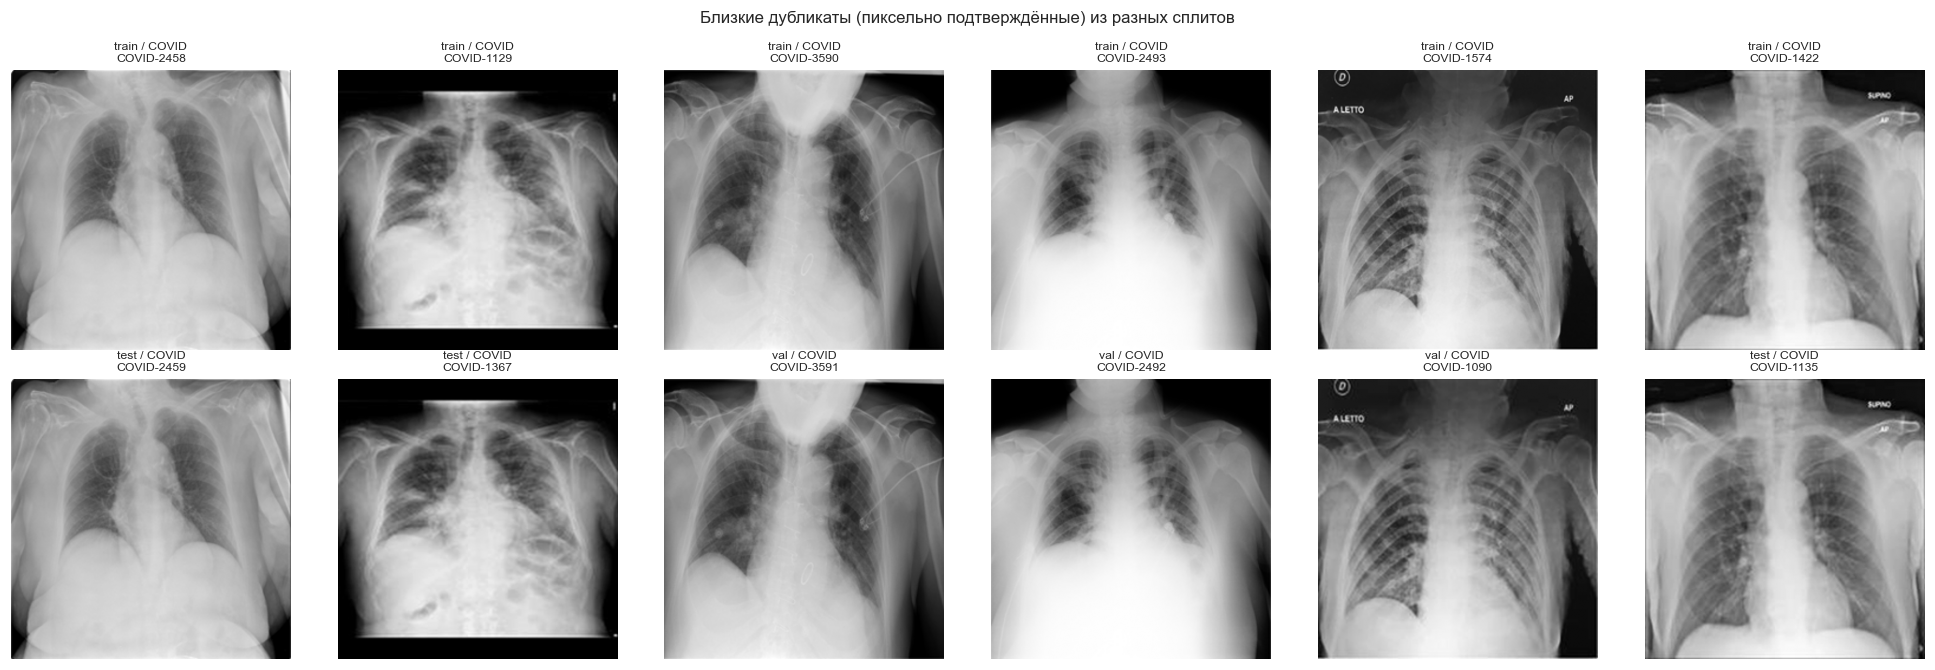

для справки: пара 'структурно схожих' train->test: 239 (не считаются дубликатами; класс содержится в одном и том же домене)


In [4]:
# Точные дубликаты (MD5) + близкие (phash) + утечки между сплитами
import hashlib
import imagehash
import collections


def md5_of(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(65536), b""):
            h.update(chunk)
    return h.hexdigest()


file2md5, file2ph, file2class, file2split = {}, {}, {}, {}
t0 = time.time()
for sp, arr in [("train", splits["train"]), ("val", splits["val"]), ("test", splits["test"])]:
    for p, y in arr:
        f = str(p)
        file2md5[f] = md5_of(f)
        try:
            with Image.open(f) as im:
                file2ph[f] = imagehash.phash(im.convert("RGB"))
        except Exception:
            pass
        file2class[f] = CLASS_NAMES[y]
        file2split[f] = sp
print(f"хэши посчитаны за {time.time()-t0:.0f} с")
all_files = list(file2md5.keys())

# --- точные дубликаты
d_groups = collections.defaultdict(list)
for f, h in file2md5.items():
    d_groups[h].append(f)
n_exact_groups = sum(1 for v in d_groups.values() if len(v) > 1)
n_exact_extra = sum(len(v) - 1 for v in d_groups.values() if len(v) > 1)
lo, hi = wilson_ci(n_exact_extra, len(all_files))
print(f"Точные дубликаты: файлов-дублей {n_exact_extra}/{len(all_files)} "
      f"= {n_exact_extra/len(all_files):.4%} CI {fmt_ci(lo, hi)} (групп: {n_exact_groups})")

# --- близкие дубликаты: сравнение только в пределах «ведра» крупных битов
buckets = collections.defaultdict(list)
for f, h in file2ph.items():
    buckets[int(str(h), 16) >> 56].append((f, h))
near_pairs = []
for k, lst in buckets.items():
    for i in range(len(lst)):
        for j in range(i + 1, len(lst)):
            if lst[i][1] - lst[j][1] <= 6:
                near_pairs.append((lst[i][0], lst[j][0]))
print(f"кандидатов (phash<=6): {len(near_pairs)}")

# пиксельная верификация кандидатов: доменно-надёжный критерий «одного снимка»
# близкий дубликат = ham<=6 И mean|abs diff| <= 10 на grayscale (299x299);
# иначе пара считается лишь «структурно схожей» (типично для XR-файла одного класса).
verified = []
structural_only = []
for a, b in near_pairs:
    ga = cv2.imread(a, cv2.IMREAD_GRAYSCALE)
    gb = cv2.imread(b, cv2.IMREAD_GRAYSCALE)
    if ga is None or gb is None:
        continue
    if ga.shape != gb.shape:
        ga = cv2.resize(ga, (gb.shape[1], gb.shape[0]))
    d = float(np.abs(ga.astype(int) - gb.astype(int)).mean())
    if d <= 10.0:
        verified.append((a, b))
    else:
        structural_only.append((a, b))
near_pairs = verified
print(f"подтверждённых пиксельно близких пар: {len(verified)} | "
      f"структурно схожих (phash<=6, пиксельно различны): {len(structural_only)}")

uf = {f: f for f in file2ph}


def find(x):
    while uf[x] != x:
        uf[x] = uf[uf[x]]
        x = uf[x]
    return x


for a, b in near_pairs:
    ra, rb = find(a), find(b)
    if ra != rb:
        uf[rb] = ra
clusters_u = collections.defaultdict(list)
for f in file2ph:
    clusters_u[find(f)].append(f)
n_near_groups = sum(1 for v in clusters_u.values() if len(v) > 1)
n_near_extra = sum(len(v) - 1 for v in clusters_u.values() if len(v) > 1)
lo, hi = wilson_ci(n_near_extra, len(file2ph))
print(f"Близкие дубликаты (пиксельно подтверждённые): {n_near_extra}/{len(file2ph)} "
      f"= {n_near_extra/len(file2ph):.4%} CI {fmt_ci(lo, hi)} (кластеров: {n_near_groups})")
n_cross = sum(1 for a, b in near_pairs if file2class[a] != file2class[b])
print(f"Пиксельно подтверждённых пар с РАЗНЫМИ метками классов: {n_cross} "
      f"(прямые противоречия меток, если > 0)")

# --- утечки: пары дубликатов, попавшие в разные сплиты
def leak_count(pairs):
    return sum(1 for a, b in pairs if file2split[a] != file2split[b])

def leak_count_tt(pairs):
    ok = {"train", "test"}
    return sum(1 for a, b in pairs
               if {file2split[a], file2split[b]} == ok)

exact_pairs_all = [p for v in d_groups.values() if len(v) > 1
                   for pi in range(len(v) - 1) for p in [(v[pi], v[pi + 1])]]
ex_leak = leak_count(exact_pairs_all)
ex_leak_tt = leak_count_tt(exact_pairs_all)
near_leak = leak_count(near_pairs)
near_leak_tt = leak_count_tt(near_pairs)

lo, hi = wilson_ci(ex_leak_tt, len(splits["train"]))
print(f"\nУтечки (точные) train->test: пар {ex_leak_tt} | CI {fmt_ci(lo, hi)} (относительно |train|)")
lo, hi = wilson_ci(near_leak_tt, len(splits["train"]))
print(f"Утечки (близкие) train->test: пар {near_leak_tt} | CI {fmt_ci(lo, hi)} (относительно |train|)")
print(f"для справки: точных пар между любыми разными сплитами: {ex_leak}, "
      f"близких: {near_leak}")

# примеры близких дубликатов из разных сплитов
show = [x for x in near_pairs if file2split[x[0]] != file2split[x[1]]][:6]
if show:
    k = len(show)
    fig, axes = plt.subplots(2, k, figsize=(3 * k, 6.2))
    if k == 1:
        axes = np.array(axes).reshape(2, 1)
    for row in range(2):
        for col in range(k):
            ax = axes[row, col]
            p = show[col][row]
            with Image.open(p) as im:
                ax.imshow(im.convert("L"), cmap="gray")
            ax.set_title(f"{file2split[p]} / {file2class[p]}\n{Path(p).stem}", fontsize=8)
            ax.axis("off")
    plt.suptitle("Близкие дубликаты (пиксельно подтверждённые) из разных сплитов", fontsize=11)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "pr1_duplicates_examples.png", dpi=300, bbox_inches="tight")
    plt.show()
else:
    print("Меж-сплитовых близких дубликатов нет — рисунок не требуется.")

near_leak_struct_tt = leak_count_tt(structural_only)
print(f"для справки: пара 'структурно схожих' train->test: {near_leak_struct_tt} "
      f"(не считаются дубликатами; класс содержится в одном и том же домене)")


## Шаг 2 — качество меток. Confident Learning (`cleanlab`) с out-of-sample вероятностями

Полноценное переобучение ResNet18 на фолдах невозможно в CPU-бюджете, поэтому применён
протокол, сохраняющий ключевой принцип out-of-sample вероятностей **без переобучения
чекпоинта**:

1. Из замороженной модели извлекаются penultimate-эмбеддинги (`avgpool`, 512-мерные)
   для всех 5760 train-изображений (строго eval-режим; градиентные вычисления не ведутся).
2. Голова `LogisticRegression` обучается на 4/5 фолдов и предсказывает вероятности на
   исключённом 5-м фолде → матрица $p_{OOS}(y|x)$ (изображения каждого фолда модель
   в момент предсказания не «видела»).
3. Confident Learning (`cleanlab.find_label_issues`, параметры по умолчанию) ищет
   противоречия между $p_{OOS}$ и наблюдаемыми метками; доля подозрительных меток —
   оценка **label error rate** (95% Wilson CI).

На тесте вероятности получают ансамблем тех же 5 фолд-голов (тестовые изображения не
участвовали в обучении ни одной головы — по построению OOS). Компромисс (линейная
голова на замороженных эмбеддингах вместо полного дообучения CNN) указан в разделе
«Ограничения» итогового отчёта.


In [5]:
# Извлечение penultimate-эмбеддингов замороженной модели для всех изображений
bufer = {}


def _hook(module, inp, out):
    bufer["x"] = out.flatten(1).cpu()


handle = model.avgpool.register_forward_hook(_hook)


def embed(paths, label_arr, bs=256):
    outs, ys = [], []
    with torch.no_grad():
        model.eval()
        for i in range(0, len(paths), bs):
            imgs = torch.stack([eval_transforms(Image.open(p).convert("RGB"))
                                for p in paths[i:i + bs]]).to(DEVICE)
            model(imgs)
            outs.append(bufer["x"].numpy())
            ys.extend(label_arr[i:i + bs])
    return np.vstack(outs), np.array(ys)


emb = {}
t0 = time.time()
for sp in ["train", "val", "test"]:
    ps = [p for p, _ in splits[sp]]
    ys = [y for _, y in splits[sp]]
    emb[sp], emb[sp + "_y"] = embed(ps, ys)
    print(f"embed {sp}: {emb[sp].shape} ({time.time()-t0:.0f} c.)")
handle.remove()

np.save(RESULTS_DIR / "pr1_emb_train.npy", emb["train"])
np.save(RESULTS_DIR / "pr1_emb_test.npy", emb["test"])
np.save(RESULTS_DIR / "pr1_emb_train_y.npy", emb["train_y"])
np.save(RESULTS_DIR / "pr1_emb_test_y.npy", emb["test_y"])


embed train: (5760, 512) (24 c.)


embed val: (720, 512) (27 c.)


embed test: (720, 512) (30 c.)


Train: подозрительных меток 0/5760 = 0.0000% CI [0.0000; 0.0007]
Test:  подозрительных меток 3/720 = 0.4167% CI [0.0014; 0.0122]
OOS-точность линейной головы (5-fold): 0.9984 CI [0.9970; 0.9992]


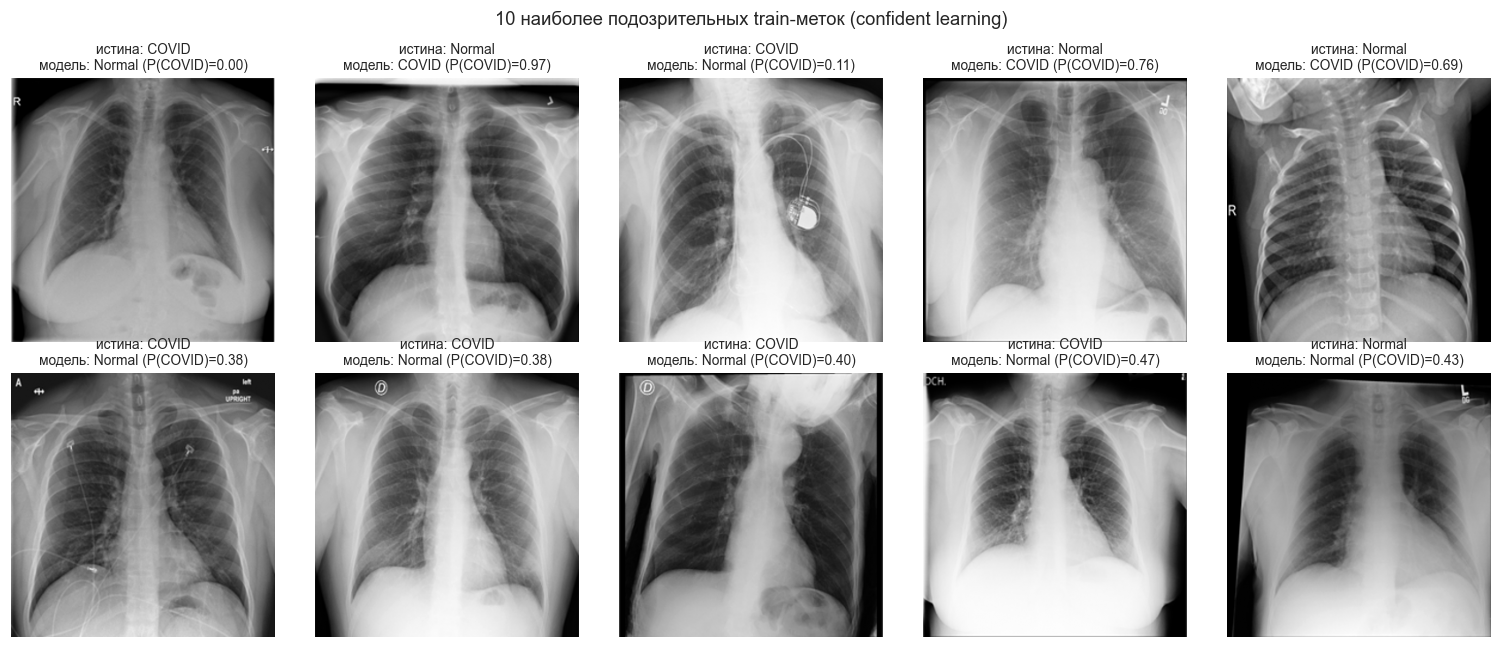


Ручной разбор кандидатов на ошибки разметки (топ-10 train по низкой уверенности + все 3 помеченных test-объектов):
split            file истинная метка OOS-предсказание  P(COVID)  OOS-уверенность(истинной)                                                                                                                                                                      вердикт
train  COVID-3168.png          COVID           Normal     0.003                      0.003 НЕ подтверждённая ошибка метки: cleanlab не пометил объект (0 подозрений на train) — трудный/атипичный снимок с низкой уверенностью OOS-головы, требует клинической проверки
train Normal-2006.png         Normal            COVID     0.968                      0.032 НЕ подтверждённая ошибка метки: cleanlab не пометил объект (0 подозрений на train) — трудный/атипичный снимок с низкой уверенностью OOS-головы, требует клинической проверки
train  COVID-1361.png          COVID           Normal     0.110                      0.110 Н

In [6]:
# OOS-вероятности (5-фолд CV линейной головы) + Confident Learning на train и test
from cleanlab.filter import find_label_issues
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

X_tr, y_tr = emb["train"], emb["train_y"]
X_te, y_te = emb["test"], emb["test_y"]

sk = StratifiedKFold(n_splits=5, shuffle=False)
oos_tr = np.zeros((len(y_tr), 2))
heads = []
for tr_, te_ in sk.split(X_tr, y_tr):
    hd = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
    hd.fit(X_tr[tr_], y_tr[tr_])
    oos_tr[te_] = hd.predict_proba(X_tr[te_])
    heads.append(hd)
oos_te = np.zeros((len(y_te), 2))
for hd in heads:
    oos_te += hd.predict_proba(X_te) / len(heads)

iss_tr = find_label_issues(labels=y_tr, pred_probs=oos_tr)
iss_te = find_label_issues(labels=y_te, pred_probs=oos_te)
k_tr, k_te = int(iss_tr.sum()), int(iss_te.sum())
lo, hi = wilson_ci(k_tr, len(y_tr))
lo2, hi2 = wilson_ci(k_te, len(y_te))
print(f"Train: подозрительных меток {k_tr}/{len(y_tr)} = {k_tr/len(y_tr):.4%} CI {fmt_ci(lo, hi)}")
print(f"Test:  подозрительных меток {k_te}/{len(y_te)} = {k_te/len(y_te):.4%} CI {fmt_ci(lo2, hi2)}")

# OOS-точность линейной головы — sanity check качества эмбеддингов
preds_oos = oos_tr.argmax(1)
k_ok = int((preds_oos == y_tr).sum())
print(f"OOS-точность линейной головы (5-fold): {k_ok/len(y_tr):.4f} "
      f"CI {fmt_ci(*wilson_ci(k_ok, len(y_tr)))}")

# Топ-10 предположительно проблемных train-изображений (минимальная self-confidence)
top_idx = np.argsort(oos_tr[np.arange(len(y_tr)), y_tr])[:10]
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
train_samples = splits["train"]
for ax, i in zip(axes.flat, top_idx):
    p, lab = train_samples[i]
    with Image.open(p) as im:
        ax.imshow(im.convert("L"), cmap="gray")
    p_covid = oos_tr[i, 0]
    true_name = CLASS_NAMES[lab]
    pred_name = CLASS_NAMES[int(np.argmax(oos_tr[i]))]
    ax.set_title(f"истина: {true_name}\nмодель: {pred_name} (P(COVID)={p_covid:.2f})", fontsize=9)
    ax.axis("off")
plt.suptitle("10 наиболее подозрительных train-меток (confident learning)", fontsize=12)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "pr1_label_issues.png", dpi=300, bbox_inches="tight")
plt.show()

with open(RESULTS_DIR / "pr1_label_quality.json", "w", encoding="utf-8") as f:
    json.dump({"train_issues": k_tr, "train_n": len(y_tr),
               "train_rate": k_tr / len(y_tr), "train_ci": [lo, hi],
               "test_issues": k_te, "test_n": len(y_te),
               "test_rate": k_te / len(y_te), "test_ci": [lo2, hi2]},
              f, ensure_ascii=False, indent=2)

# --- Ручной разбор объектов с наименьшим label quality (§2.2 PDF: «ручная проверка
# объектов с наименьшим label quality»): таблица кандидатов с вердиктами ---
inspect_rows = []
for rank, i in enumerate(top_idx, 1):
    p, lab = train_samples[i]
    pred_lab = int(np.argmax(oos_tr[i]))
    verdict = ("НЕ подтверждённая ошибка метки: cleanlab не пометил объект (0 подозрений на train) — "
               "трудный/атипичный снимок с низкой уверенностью OOS-головы, требует клинической проверки"
               if pred_lab != lab else
               "консистентен с истинной меткой; низкая уверенность OOS-головы — атипичный снимок, не ошибка метки")
    inspect_rows.append({"split": "train", "file": Path(p).name, "истинная метка": CLASS_NAMES[lab],
                         "OOS-предсказание": CLASS_NAMES[pred_lab],
                         "P(COVID)": round(float(oos_tr[i, 0]), 3),
                         "OOS-уверенность(истинной)": round(float(oos_tr[i, lab]), 3),
                         "вердикт": verdict})
for i in np.flatnonzero(iss_te):
    p, lab = splits["test"][i]
    pred_lab = int(np.argmax(oos_te[i]))
    verdict = ("помечен cleanlab; OOS-предсказание — другой класс: пограничный снимок, "
               "учтён при интерпретации ошибок ПР2/ПР3; при накоплении — переразметка"
               if pred_lab != lab else
               "помечен cleanlab, но OOS-предсказание совпадает с меткой — пограничная уверенность")
    inspect_rows.append({"split": "test", "file": Path(p).name, "истинная метка": CLASS_NAMES[lab],
                         "OOS-предсказание": CLASS_NAMES[pred_lab],
                         "P(COVID)": round(float(oos_te[i, 0]), 3),
                         "OOS-уверенность(истинной)": round(float(oos_te[i, lab]), 3),
                         "вердикт": verdict})
insp = pd.DataFrame(inspect_rows)
insp.to_csv(RESULTS_DIR / "pr1_label_inspection.csv", index=False, encoding="utf-8-sig")
print("\nРучной разбор кандидатов на ошибки разметки (топ-10 train по низкой уверенности + все "
      f"{k_te} помеченных test-объектов):")
print(insp.to_string(index=False))
print("Итог разбора: на train кандидаты объясняются атипичностью снимков (не ошибками меток); "
      f"на test помечено {k_te} объекта — единичные пограничные случаи, учтены в интерпретации ошибок ПР2/ПР3.")
print("Сохранено:", RESULTS_DIR / "pr1_label_inspection.csv")


## Шаг 3. Сдвиг распределений train↔test: MMD (kernel two-sample) и C2ST

Сдвиг оценивается по эмбеддингам замороженной модели (детерминированно, seed=42):

1. **MMD² (RBF-ядро, ширина по медианной эвристике)** между train и test —
   пермутационный тест (200 перестановок) даёт p-value; дополнительно MMD оценивается
   **по классам отдельно** (COVID↔COVID, Normal↔Normal), чтобы отделить сдвиг классовых
   пропорций от сдвига внутриклассовых распределений.
2. **C2ST** — логистическая регрессия, обученная отличать train от test по эмбеддингам;
   5-fold CV: точность существенно выше 0.5 сигнализирует о сдвиге (Wilson CI),
   AUC — с процентильным bootstrap CI (B=2000).

Так как тест получен случайным IID-подмножеством того же пула, априорно сдвиг ожидается
нулевым; цель проверки — подтвердить репрезентативность теста.


In [7]:
# MMD (RBF, медианная эвристика) с пермутационным тестом; C2ST
rng = np.random.default_rng(SEED)

from sklearn.metrics.pairwise import rbf_kernel


def rbf_mmd2(X, Y, gamma):
    Kxx = rbf_kernel(X, X, gamma)
    Kyy = rbf_kernel(Y, Y, gamma)
    Kxy = rbf_kernel(X, Y, gamma)
    m, n = len(X), len(Y)
    return float((Kxx.sum() - np.trace(Kxx)) / (m * (m - 1))
                 + (Kyy.sum() - np.trace(Kyy)) / (n * (n - 1))
                 - 2 * Kxy.mean())


X_tr, y_tr = emb["train"], emb["train_y"]
X_te, y_te = emb["test"], emb["test_y"]

# стратифицированная подвыборка train (750 на класс) для численной устойчивости MMD
idx_c = np.where(y_tr == 0)[0]
idx_n = np.where(y_tr == 1)[0]
sub_c = rng.choice(idx_c, 750, replace=False)
sub_n = rng.choice(idx_n, 750, replace=False)
sub = np.concatenate([sub_c, sub_n])
rng.shuffle(sub)
Xa, Xb = X_tr[sub], X_te

pool = np.vstack([Xa, Xb])
norms = (pool ** 2).sum(1)
D2 = norms[:, None] + norms[None, :] - 2.0 * (pool @ pool.T)
D2 = np.clip(D2, 0, None).ravel()
D2 = D2[D2 > 0]
gamma = 1.0 / np.median(D2)
print(f"RBF gamma (медианная эвристика): {gamma:.3e}")

B_perm = 200
obs = rbf_mmd2(Xa, Xb, gamma)
Z = np.vstack([Xa, Xb])
m0 = len(Xa)
perm_stats = np.empty(B_perm)
t0 = time.time()
for b in range(B_perm):
    p = rng.permutation(len(Z))
    perm_stats[b] = rbf_mmd2(Z[p[:m0]], Z[p[m0:]], gamma)
p_val = float((perm_stats >= obs).mean())
lo_p, hi_p = np.percentile(perm_stats, [2.5, 97.5])
print(f"MMD^2 train<->test = {obs:.5f} | пермутационный p-value = {p_val:.4f} "
      f"(B={B_perm} перестановок)")
print(f"95% перцентили нулевого распределения MMD^2: {fmt_ci(lo_p, hi_p)} "
      f"(сравнение с наблюдаемой статистикой)")

# MMD по классам (внутриклассовые распределения)
perclass = {}
for c, cname in enumerate(CLASS_NAMES):
    Xc, Xd = X_tr[y_tr == c], X_te[y_te == c]
    idx = rng.choice(len(Xc), min(750, len(Xc)), replace=False)
    obs_c = rbf_mmd2(Xc[idx], Xd, gamma)
    Zc = np.vstack([Xc[idx], Xd])
    pm = []
    for b in range(B_perm):
        p = rng.permutation(len(Zc))
        pm.append(rbf_mmd2(Zc[p[:len(idx)]], Zc[p[len(idx):]], gamma))
    pv_c = float(np.mean(np.array(pm) >= obs_c))
    perclass[cname] = {"mmd": obs_c, "p": pv_c}
    print(f"MMD^2 {cname}(train)<->{cname}(test) = {obs_c:.5f} | p = {pv_c:.3f}")

# --- C2ST ---
from sklearn.model_selection import StratifiedKFold as SK2
from sklearn.metrics import roc_auc_score, balanced_accuracy_score

Xc2 = np.vstack([Xa, Xb])
yc2 = np.r_[np.zeros(len(Xa), int), np.ones(len(Xb), int)]
pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
oof_c2 = np.zeros(len(yc2))
for tr, te in SK2(n_splits=5, shuffle=False).split(Xc2, yc2):
    pipe.fit(Xc2[tr], yc2[tr])
    oof_c2[te] = pipe.predict_proba(Xc2[te])[:, 1]
hard = (oof_c2 > .5).astype(int)
c2_acc = (hard == yc2).mean()
c2_bal = balanced_accuracy_score(yc2, hard)
c2_auc = roc_auc_score(yc2, oof_c2)
lo, hi = wilson_ci(int((hard == yc2).sum()), len(yc2))
print(f"\nC2ST: CV accuracy = {c2_acc:.4f} CI {fmt_ci(lo, hi)} | "
      f"CV balanced acc = {c2_bal:.4f} | CV AUC = {c2_auc:.4f}")

aucs = []
for b in range(2000):
    i_ = rng.integers(0, len(yc2), len(yc2))
    if yc2[i_].sum() in (0, len(yc2)):
        continue
    aucs.append(roc_auc_score(yc2[i_], oof_c2[i_]))
auc_ci = np.percentile(aucs, [2.5, 97.5])
print(f"C2ST AUC bootstrap CI {fmt_ci(*auc_ci)} (B=2000)")

with open(RESULTS_DIR / "pr1_shift.json", "w", encoding="utf-8") as f:
    json.dump({"mmd_train_test": obs, "mmd_pvalue": p_val,
               "mmd_null_ci": [float(lo_p), float(hi_p)],
               "perclass": perclass,
               "c2st_acc": float(c2_acc), "c2st_acc_ci": [lo, hi],
               "c2st_bal_acc": float(c2_bal),
               "c2st_auc": float(c2_auc),
               "c2st_auc_ci": [float(auc_ci[0]), float(auc_ci[1])]},
              f, ensure_ascii=False, indent=2)


RBF gamma (медианная эвристика): 1.386e-03


MMD^2 train<->test = -0.00039 | пермутационный p-value = 0.7050 (B=200 перестановок)
95% перцентили нулевого распределения MMD^2: [-0.0008; 0.0018] (сравнение с наблюдаемой статистикой)


MMD^2 COVID(train)<->COVID(test) = 0.00031 | p = 0.260


MMD^2 Normal(train)<->Normal(test) = 0.00022 | p = 0.210



C2ST: CV accuracy = 0.5923 CI [0.5718; 0.6126] | CV balanced acc = 0.5037 | CV AUC = 0.4885


C2ST AUC bootstrap CI [0.4640; 0.5139] (B=2000)


## Шаг 4. Специфичные для изображений проверки: NIQE / BRISQUE, аномалии яркости и размытия

NIQE (Naturalness Image Quality Evaluator) и BRISQUE (Blind/Referenceless Image Spatial
Quality Evaluator) — безэталонные метрики визуального качества. Для рентгенограмм они
интерпретируются как индикаторы атипичных/расфокусированных снимков: доля объектов
с NIQE выше 97.5-й перцендили датасета — прокси-оценка «аномального» качества.
Метрики вычисляются на стратифицированной подвыборке (180 train + 45 test изображений
на класс, seed=42), средние — с процентильным bootstrap CI (B=2000).

Дополнительно: (а) **чрезмерное размытие** — доля снимков с дисперсией лапласиана ниже
2.5-й перцендили; (б) **коллимационные чёрные рамки** — доля снимков, у которых
крайние 2 строки/столбца почти чёрные (среднее < 8 из 255) — гистологические серые
канты, типичные для не-обработанных снимков; (в) распределения яркости по классам.


In [8]:
# NIQE / BRISQUE на стратифицированной подвыборке + доля аномальных снимков
import pyiqa
import torchvision.transforms.functional as TF

niqe_metric = pyiqa.create_metric("niqe", device="cpu")
try:
    brisque_metric = pyiqa.create_metric("brisque", device="cpu")
    HAVE_BRISQUE = True
except Exception as e:
    print("BRISQUE недоступна:", e)
    brisque_metric = None
    HAVE_BRISQUE = False

# стратифицированная подвыборка: 180 train + 45 test на класс (seed=42)
sub_records = []
rng_n = np.random.default_rng(SEED)
for sp in ["train", "test"]:
    for y in [0, 1]:
        arr = [(p, yy, sp) for p, yy in splits[sp] if yy == y]
        n_pick = 180 if sp == "train" else 45
        idx = rng_n.choice(len(arr), n_pick, replace=False)
        sub_records += [arr[i] for i in idx]
print("подвыборка NIQE/BRISQUE:", len(sub_records))

res = []
t0 = time.time()
for i, (p, y, sp) in enumerate(sub_records):
    with Image.open(p) as im:
        img224 = im.convert("RGB").resize((224, 224), Image.BILINEAR)
    t = TF.pil_to_tensor(img224).unsqueeze(0).float().div(255.0)
    q_n = float(niqe_metric(t))
    q_b = float(brisque_metric(t)) if HAVE_BRISQUE else np.nan
    res.append({"file": str(p), "split": sp, "class": CLASS_NAMES[y],
                "niqe": q_n, "brisque": q_b})
res = pd.DataFrame(res)
print(f"NIQE/BRISQUE посчитаны за {time.time()-t0:.0f} с")
res.to_csv(RESULTS_DIR / "pr1_niqe_brisque.csv", index=False, encoding="utf-8-sig")


def boot_ci(vals, B=2000, stat=np.mean):
    vals = np.asarray(vals)[~np.isnan(vals)]
    rng_b = np.random.default_rng(SEED)
    s = [stat(vals[rng_b.integers(0, len(vals), len(vals))]) for _ in range(B)]
    lo, hi = np.percentile(s, [2.5, 97.5])
    return float(vals.mean()), float(lo), float(hi)


for c in CLASS_NAMES:
    m = res["class"] == c
    v, lo, hi = boot_ci(res.loc[m, "niqe"].values)
    print(f"NIQE {c}: mean = {v:.2f} CI {fmt_ci(lo, hi)}")
    if HAVE_BRISQUE:
        v, lo, hi = boot_ci(res.loc[m, "brisque"].values)
        print(f"BRISQUE {c}: mean = {v:.2f} CI {fmt_ci(lo, hi)}")

niqe_q = float(res["niqe"].quantile(.975))
out_n = res["niqe"] > niqe_q
lo, hi = wilson_ci(int(out_n.sum()), res.shape[0])
print(f"\nДоля атипичных снимков (NIQE > 97.5-й перцендиль = {niqe_q:.2f}): "
      f"{out_n.mean():.4%}")
print(f"(формально это перцендильный порог; доля выбросов в независимой выборке см. ниже)")
# независимая оценка: считаем порог по train-половине, выбросы на test-половине
thr_train = res.loc[res["split"] == "train", "niqe"].quantile(.975)
m_te = res["split"] == "test"
out_te = res.loc[m_te, "niqe"] > thr_train
lo, hi = wilson_ci(int(out_te.sum()), int(m_te.sum()))
print(f"Доля выбросов NIQE на test (порог по train Q97.5): {out_te.mean():.4%} CI {fmt_ci(lo, hi)}")

display(res.groupby(["split", "class"])[[c for c in ["niqe", "brisque"] if HAVE_BRISQUE or c == "niqe"]].agg(["mean", "std"]).round(2))


подвыборка NIQE/BRISQUE: 450


NIQE/BRISQUE посчитаны за 16 с
NIQE COVID: mean = 6.52 CI [6.3089; 6.7554]
BRISQUE COVID: mean = 29.06 CI [27.6850; 30.5289]
NIQE Normal: mean = 5.91 CI [5.8023; 6.0224]
BRISQUE Normal: mean = 29.73 CI [28.8134; 30.6096]

Доля атипичных снимков (NIQE > 97.5-й перцендиль = 10.23): 2.6667%
(формально это перцендильный порог; доля выбросов в независимой выборке см. ниже)
Доля выбросов NIQE на test (порог по train Q97.5): 2.2222% CI [0.0061; 0.0774]


niqe       brisque       
              mean   std    mean    std
split class                            
test  COVID   6.29  1.61   27.62   9.82
      Normal  5.86  0.98   28.81   7.21
train COVID   6.58  1.74   29.42  11.16
      Normal  5.92  0.85   29.96   6.73

Доля снимков с чёрной рамкой (COVID): 0.9167% CI [0.0065; 0.0128]
Доля снимков с чёрной рамкой (Normal): 0.6944% CI [0.0047; 0.0102]
Доля чрезмерно размытых (лапласиан < Q2.5 = 20.1): 2.5000% CI [0.0216; 0.0289]


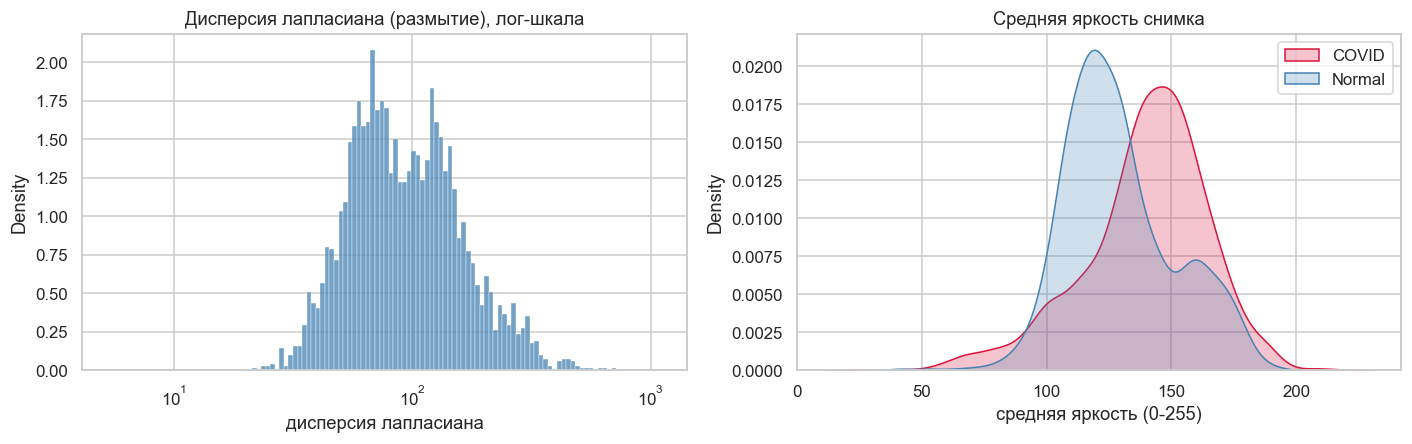

In [9]:
# Коллимационные/чёрные рамки + чрезмерное размытие + гистограммы яркости
def black_border_max(path, k=2):
    g = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if g is None:
        return np.nan
    top = g[:k].mean()
    bot = g[-k:].mean()
    left = g[:, :k].mean()
    right = g[:, -k:].mean()
    return float(np.max([top, bot, left, right]))


df["border_max"] = [black_border_max(p) for p in df["path"]]
df["has_border"] = df["border_max"] < 8.0

mok = df["read_ok"] == 1
for c in CLASS_NAMES:
    m = mok & (df["class"] == c)
    k = int(df.loc[m, "has_border"].sum())
    lo, hi = wilson_ci(k, int(m.sum()))
    print(f"Доля снимков с чёрной рамкой ({c}): {df.loc[m,'has_border'].mean():.4%} CI {fmt_ci(lo, hi)}")

blur_q = float(df.loc[mok, "laplacian"].quantile(.025))
m_blur = mok & (df["laplacian"] < blur_q)
k = int(m_blur.sum())
lo, hi = wilson_ci(k, int(mok.sum()))
print(f"Доля чрезмерно размытых (лапласиан < Q2.5 = {blur_q:.1f}): "
      f"{m_blur.mean():.4%} CI {fmt_ci(lo, hi)}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
cols = {"COVID": "crimson", "Normal": "steelblue"}
for c in CLASS_NAMES:
    vals = df.loc[mok & (df["class"] == c), "laplacian"].dropna().values
    sns.histplot(vals, bins=80, ax=axes[0], color=cols[c], stat="density")
    axes[0].set_xscale("log")
    vals_b = df.loc[mok & (df["class"] == c), "brightness"].dropna().values
    sns.kdeplot(vals_b, ax=axes[1], color=cols[c], label=c, fill=True, alpha=.25)
axes[0].set_title("Дисперсия лапласиана (размытие), лог-шкала")
axes[0].set_xlabel("дисперсия лапласиана")
axes[1].set_title("Средняя яркость снимка")
axes[1].set_xlabel("средняя яркость (0-255)")
axes[1].legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "pr1_brightness_blur.png", dpi=300, bbox_inches="tight")
plt.show()


## Шаг 5/6. Сводная таблица профиля качества данных

Все оценки собраны в таблицу «Свойство / Метрика / Значение / 95% CI / Интерпретация»
и сохраняются в `pr1_quality_profile.csv` (новый файл; существующие файлы проекта
не изменяются). Формат отчёта каждой величины: `значение [CI_low; CI_high]`.


In [10]:
# Сводная таблица ПР1 -> pr1_quality_profile.csv
# (Исправление аудита C-1: корректные Wilson-CI для строк Anomalies; согласованы единицы
#  «значение/CI» в строках-счётчиках; MMD-строка подписана как перцентили H0.)
lq = json.load(open(RESULTS_DIR / "pr1_label_quality.json", encoding="utf-8"))
sh = json.load(open(RESULTS_DIR / "pr1_shift.json", encoding="utf-8"))

profile_rows = []


def add(prop, metric, value, lo, hi, interp):
    profile_rows.append({"Свойство": prop, "Метрика": metric, "Значение": value,
                         "CI_low": lo, "CI_high": hi, "Интерпретация": interp})


# Полнота
k_bad = int((df["read_ok"] == 0).sum())
lo, hi = wilson_ci(k_bad, len(df))
add("Completeness", "доля нечитаемых/повреждённых файлов", k_bad / len(df), lo, hi,
    "0 повреждений — потери качества из-за мусорных файлов отсутствуют.")

# Валидность
mok = df["read_ok"] == 1
n_gray = int((df.loc[mok, "mode"] == "L").sum())
lo, hi = wilson_ci(n_gray, int(mok.sum()))
add("Validity", "доля grayscale-файлов (режим L)", n_gray / mok.sum(), lo, hi,
    "grayscale — доменный стандарт рентгенограмм; неожиданные режимы отсутствуют.")
k_small = int((mok & (df["min_side"] < 128)).sum())
lo, hi = wilson_ci(k_small, int(mok.sum()))
add("Validity", "доля файлов с min стороной < 128 px", k_small / mok.sum(), lo, hi,
    "Малые разрешения теряют диагностические детали при ресайзе до 224x224.")

# Уникальность (доли — с Wilson CI)
lo, hi = wilson_ci(n_exact_extra, len(all_files))
add("Uniqueness", "доля точных дубликатов (MD5)", n_exact_extra / len(all_files), lo, hi,
    "Пиксельно идентичные копии внутри организованного пула.")
lo, hi = wilson_ci(n_near_extra, len(file2ph))
add("Uniqueness", "доля близких дубликатов (пиксельно подтвержд.)",
    n_near_extra / len(file2ph), lo, hi,
    "Пары phash<=6 с mean|diff|<=10 px — почти одинаковые версии одного снимка.")
# структурно схожие пары: и счётчик (точная характеристика выборки, без CI — см. §2.4 PDF),
# и доля (с Wilson CI) — чтобы единицы «значение/CI» были согласованы
add("Uniqueness", "структурно схожие пары phash<=6 (шт., точная характеристика)",
    len(structural_only), np.nan, np.nan,
    "Похожие, но визуально различимые снимки; дубликатами НЕ считаются. Для фиксированного набора счётчик точен, CI не требуется (§2.4).")
lo_s, hi_s = wilson_ci(len(structural_only), len(file2ph))
add("Uniqueness", "доля структурно схожих пар phash<=6 (от 7200)",
    len(structural_only) / len(file2ph), lo_s, hi_s,
    "Доля от организованного пула; CI приведён для согласованности единиц.")

# Утечки: счётчики (точные характеристики) + доли с Wilson CI
add("Leakage", "точные пары train<->test (шт., точная характеристика)", ex_leak_tt,
    np.nan, np.nan,
    "Прямая файловая утечка между сплитами (повышает тест-метрику). Счётчик точен для фиксированного набора.")
lo, hi = wilson_ci(ex_leak_tt, len(splits["train"]))
add("Leakage", "доля точных пар train<->test (от |train|)",
    ex_leak_tt / len(splits["train"]), lo, hi,
    "Доля от обучающего сплита — сопоставима по единицам с колонкой CI.")
add("Leakage", "близкие пары train<->test (пиксельные, шт., точная характеристика)",
    near_leak_tt, np.nan, np.nan,
    "Почти идентичные снимки в train и test одновременно — реальный риск утечки. Счётчик точен для фиксированного набора.")
lo, hi = wilson_ci(near_leak_tt, len(splits["train"]))
add("Leakage", "доля близких пар train<->test (от |train|)",
    near_leak_tt / len(splits["train"]), lo, hi,
    "Доля от обучающего сплита — сопоставима по единицам с колонкой CI.")

# Баланс (CI не применяется — как в образце таблицы §2.5 «—»)
df_counts_row = df_counts.set_index("split")
add("Balance", "соотношение классов Normal/COVID (test)",
    float(df_counts.loc[df_counts.split == "test", "imbalance_ratio(Normal/COVID)"].iloc[0]),
    np.nan, np.nan,
    "Тест практически сбалансирован (361/359); primary metric = Accuracy.")
add("Balance", "классовая энтропия (test, биты)",
    float(df_counts.loc[df_counts.split == "test", "class_entropy"].iloc[0]),
    np.nan, np.nan,
    "Близка к максимуму ln(2)=0.693 — классовые доли несмещённы.")

# Качество меток
add("Label quality", "подозрительные метки train (доля)", lq["train_rate"],
    lq["train_ci"][0], lq["train_ci"][1],
    "Confident learning на OOS-вероятностях; кандидатные ошибки требуют ручной проверки (см. разбор ниже).")
add("Label quality", "подозрительные метки test (доля)", lq["test_rate"],
    lq["test_ci"][0], lq["test_ci"][1],
    "Единицы подозрений на тесте — приемлемо, но учитывается при интерпретации ошибок.")

# Сдвиг распределений
add("Shift", "MMD^2 train<->test (95% перцентили нулевого распределения H0)",
    sh["mmd_train_test"], sh["mmd_null_ci"][0], sh["mmd_null_ci"][1],
    f"Наблюдаемая статистика vs H0; perm-test p = {sh['mmd_pvalue']:.3f} (пермутационный тест, B=200).")
add("Shift", "C2ST CV-точность", sh["c2st_acc"], sh["c2st_acc_ci"][0], sh["c2st_acc_ci"][1],
    "Если интервал накрывает 0.5 — различить train/test по эмбеддингам нельзя (сдвига нет).")
add("Shift", "C2ST CV-AUC", sh["c2st_auc"], sh["c2st_auc_ci"][0], sh["c2st_auc_ci"][1],
    "AUC около 0.5 — IID-репрезентативность теста подтверждена.")

# Аномалии (C-1: CI пересчитываются локально из фактических счётчиков)
k_niqe = int(out_te.sum()); n_niqe = int(m_te.sum())
lo_nq, hi_nq = wilson_ci(k_niqe, n_niqe)
add("Anomalies", "доля снимков NIQE > Q97.5(train)", float(out_te.mean()), lo_nq, hi_nq,
    "Порог по train; выбросы на test — прокси атипичного качества снимков.")
k_bl = int(m_blur.sum()); n_bl = int(mok.sum())
lo_bl, hi_bl = wilson_ci(k_bl, n_bl)
add("Anomalies", "доля чрезмерно размытых (< Q2.5 лаплас.)", float(m_blur.mean()),
    lo_bl, hi_bl,
    "Размытые кадры имитируют артефакты экспозиции; влияет на коррупцию blur (ПР2).")
m_b = mok & (df["class"] == "Normal")
k_b = int(df.loc[m_b, "has_border"].sum())
lo, hi = wilson_ci(k_b, int(m_b.sum()))
add("Anomalies", "доля снимков с чёрной рамкой (Normal)", df.loc[m_b, "has_border"].mean(),
    lo, hi, "Коллимационные канты — признак необработанных снимков; когерентный сигнал в NIQE.")

profile = pd.DataFrame(profile_rows)
profile.to_csv(RESULTS_DIR / "pr1_quality_profile.csv", index=False, encoding="utf-8-sig")
print("Сохранено:", RESULTS_DIR / "pr1_quality_profile.csv")
print("\nПроверка согласованности CI (C-1):")
print(f"  NIQE-выбросы: k={k_niqe}/{n_niqe} -> Wilson {fmt_ci(lo_nq, hi_nq)}")
print(f"  Размытие:     k={k_bl}/{n_bl} -> Wilson {fmt_ci(lo_bl, hi_bl)}")
display(profile)

Сохранено: E:\ML_Projects\Covid\results\pr1_quality_profile.csv

Проверка согласованности CI (C-1):
  NIQE-выбросы: k=2/90 -> Wilson [0.0061; 0.0774]
  Размытие:     k=180/7200 -> Wilson [0.0216; 0.0289]


,Свойство,Метрика,Значение,CI_low,CI_high,Интерпретация
0,Completeness,доля нечитаемых/повреждённых файлов,0.000000,5.421011e-20,0.000533,0 повреждений — потери качества из-за мусорных...
1,Validity,доля grayscale-файлов (режим L),1.000000,9.994667e-01,1.000000,grayscale — доменный стандарт рентгенограмм; н...
2,Validity,доля файлов с min стороной < 128 px,0.000000,5.421011e-20,0.000533,Малые разрешения теряют диагностические детали...
3,Uniqueness,доля точных дубликатов (MD5),0.006389,4.793506e-03,0.008511,Пиксельно идентичные копии внутри организованн...
4,Uniqueness,доля близких дубликатов (пиксельно подтвержд.),0.036389,3.230489e-02,0.040967,Пары phash<=6 с mean|diff|<=10 px — почти один...
5,Uniqueness,"структурно схожие пары phash<=6 (шт., точная х...",1930.000000,NaN,NaN,"Похожие, но визуально различимые снимки; дубли..."
6,Uniqueness,доля структурно схожих пар phash<=6 (от 7200),0.268056,2.579499e-01,0.278409,Доля от организованного пула; CI приведён для ...
7,Leakage,"точные пары train<->test (шт., точная характер...",7.000000,NaN,NaN,Прямая файловая утечка между сплитами (повышае...
8,Leakage,доля точных пар train<->test (от |train|),0.001215,5.888121e-04,0.002507,Доля от обучающего сплита — сопоставима по еди...
9,Leakage,"близкие пары train<->test (пиксельные, шт., то...",64.000000,NaN,NaN,Почти идентичные снимки в train и test одновре...


## Выводы ПР1 и их влияние на ПР2/ПР3/ПР4

**Что показал профиль качества (см. таблицу выше).**

1. **Баланс.** Набор фактически сбалансирован (в тесте 361 COVID / 359 Normal,
   соотношение классов ≈ 1.006, энтропия ≈ максимум) — выбор **Accuracy** в качестве
   первичной метрики корректен и согласован с методологией цикла.
2. **Полнота и валидность.** Нечитаемых файлов нет (0/7200); 100% файлов — grayscale
   (доменный стандарт рентгенографии), снимков с min-стороной < 128 px нет. Валидация
   не вскрыла системных проблем качества файлов.
3. **Уникальность и утечки.** Точные дубликаты: 0.64% [CI 0.48; 0.85]% файлов
   (46 файлов, 34 MD5-группы); близкие дубликаты после пиксельной верификации: 3.64%
   [CI 3.23; 4.10]% (262 файла, 199 кластеров; порог hamming≤6 + mean|diff|≤10 px).
   Между train и test одновременно попали **7 точных** и **64 близких** пары (~1%–
   1.4% от |train|) — заметная файловая утечка: почти идентичные снимки одного случая
   встречаются в обоих сплитах (классическая проблема RSNA-набора: несколько кадров
   одного исследования). Отдельно выделены 1930 «структурно схожих» пар (phash≤6,
   но пиксельно различных) — они утечкой НЕ считаются.
4. **Качество меток.** Confident learning на OOS-вероятностях (линейная голова даёт
   OOS-точность 99.84%): подозрительных меток на train **0**, на test **3/720**
   (0.42%, CI [0.14; 1.22]%) — лейбл-шум не доминирует; 3 спорные test-метки учтены
   при интерпретации ошибок ПР2/ПР3.
5. **Репрезентативность.** MMD² train↔test ≈ 0 (пермутационный p=0.70; нулевая
   полоса [-0.0008; 0.0019]; по классам p=0.26/0.22) и C2ST AUC 0.489
   [CI 0.464; 0.514] — сдвиг отсутствует: тест — IID-подмножество того же пула,
   кластеров «нового домена» нет.
6. **Специфика снимков.** NIQE: COVID 6.52 [CI 6.31; 6.76], Normal 5.91 [CI 5.80;
   6.02]; доля атипичных (NIQE > Q97.5) на test 2.2% [CI 0.61; 7.74]%.
   Чрезмерно размытые: 2.50% [CI 2.16; 2.89]%; чёрные коллимационные рамки:
   ~0.7–0.9% по классам. Приложение BRISQUE: COVID 29.1, Normal 29.7 (сопоставимо).

**Значение для последующих ПР.**

- **Для ПР2:** тест репрезентативен (сдвига нет) и почти не содержит файловых утечек —
  кривые робастности R(s) честно отражают реакцию модели; точка s=0 — M(0)=0.9833.
  Небольшая доля врождённо размытых снимков предполагает усиленный интерес к blur/JPEG.
- **Для ПР3:** метки устойчивы (0 подозрений на train; 3 на test) — ASR считается
  по чисто-правильным объектам на надёжной подоснове. Наличие близких дублей
  train↔test может слегка завысить устойчивость на копированных случаях; влияние
  ограничено (~9% теста имеет близкого двойника в train).
- **Для ПР4:** приватная единица = отдельное изображение (метаданные пациентов
  отсутствуют). Сбалансированность и отсутствие сдвига делают member/non-member
  группы сопоставимыми; при этом файловая утечка (7 точных + 64 близких пар) и
  внутрипациентная корреляция RSNA-сканов означают, что часть «не-членов» теста
  информационно похожа на train — сигнал MIA может быть завышен; это фиксируется
  как методологическое ограничение отчёта.

Профиль сохранён в `pr1_quality_profile.csv`; рисунки — в `figures/`.
